# 🍷 Kırmızı Şarap Kalitesi Analizi: EDA, Korelasyon ve Sınıf Dengeleme (Wine Quality Analysis)

Bu çalışmada, Portekiz'in ünlü "Vinho Verde" kırmızı şarabının fizikokimyasal test sonuçları ve uzman kalite puanları (0-10) analiz edilmektedir.

---

### 🎯 Odak Alanları:
1. **Veri Kalitesi & Temizlik:** Eksik değerlerin (Null) ve mükerrer satırların (Duplicates) tespiti ve ayıklanması.
2. **Korelasyon Analizi (Seaborn Heatmap):** Alkol, sitrik asit, uçucu asitlik ve pH'ın şarap kalitesi üzerindeki etkileri.
3. **Çok Değişkenli Dağılım:** Scatterplot ve Barplot ile kalite sınıflarının dağılımı.
4. **Dengesiz Sınıf Çözümü (SMOTE):** Düşük ve yüksek puanlı nadir sınıfların sentetik örnekleme ile dengelenmesi.


In [1]:
import pandas as pd

df_wine = pd.read_csv("winequality-red.csv")
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [2]:
df_wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [3]:
#1) Kategorik ve string datalar var mı ? Varsa bunları nasıl nümerik değerlere çevirebilir(Encoding)

In [4]:
# 2) Null veriler var mı kontrol et.
df_wine.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [5]:
df_wine.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

In [6]:
df_wine["quality"].unique()

array([5, 6, 7, 4, 8, 3])

In [7]:
df_wine["quality"].value_counts()

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

In [8]:
# df içinde "Name" sütununda kaç adet benzersiz (unique) isim oldugunu bulun. Eksik(NAN) değerleri sayma

import pandas as pd

data = {
    "Name": ["Ali","Ayşe","Mehmet",None],
    "Age": [25,None,30,22],
    "Score" : [90,85,None,88]
}

df = pd.DataFrame(data)
df["Name"].nunique()

3

In [9]:
df_wine.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [10]:
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [11]:
# 3) Duplicate(Tekrar eden veri) var mı? Kontrol et
df_wine[df_wine.duplicated()]

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4,7.4,0.700,0.00,1.90,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
11,7.5,0.500,0.36,6.10,0.071,17.0,102.0,0.99780,3.35,0.80,10.5,5
27,7.9,0.430,0.21,1.60,0.106,10.0,37.0,0.99660,3.17,0.91,9.5,5
40,7.3,0.450,0.36,5.90,0.074,12.0,87.0,0.99780,3.33,0.83,10.5,5
65,7.2,0.725,0.05,4.65,0.086,4.0,11.0,0.99620,3.41,0.39,10.9,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1563,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1564,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1567,7.2,0.695,0.13,2.00,0.076,12.0,20.0,0.99546,3.29,0.54,10.1,5
1581,6.2,0.560,0.09,1.70,0.053,24.0,32.0,0.99402,3.54,0.60,11.3,5


In [12]:
df_wine.drop_duplicates(inplace= True)
df_wine.shape

(1359, 12)

In [13]:
df_wine["quality"].value_counts()

quality
5    577
6    535
7    167
4     53
8     17
3     10
Name: count, dtype: int64

In [14]:
# Önce tekrar eden verileri sil. Data data dengeli mi diye kontrol et
df_wine["quality"].value_counts() # Dengesiz ver isetlerinde Up sampling tekrar eden veri oluşturur.

quality
5    577
6    535
7    167
4     53
8     17
3     10
Name: count, dtype: int64

<Axes: >

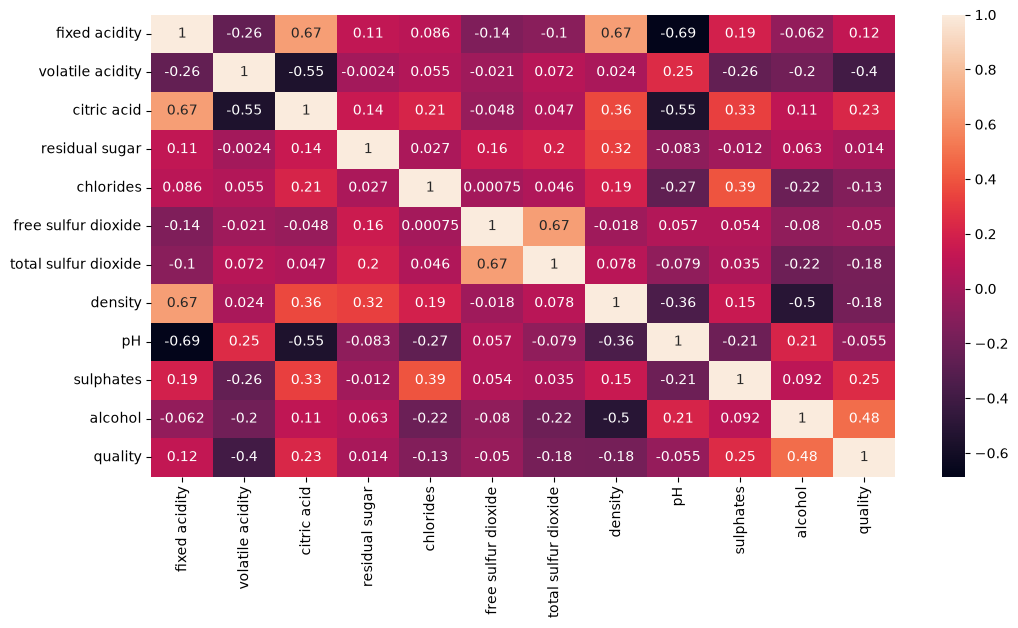

In [15]:
#correlation
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize = (12,6))
sns.heatmap(df_wine.corr(), annot= True)

In [16]:
df_wine["quality"].value_counts()

quality
5    577
6    535
7    167
4     53
8     17
3     10
Name: count, dtype: int64

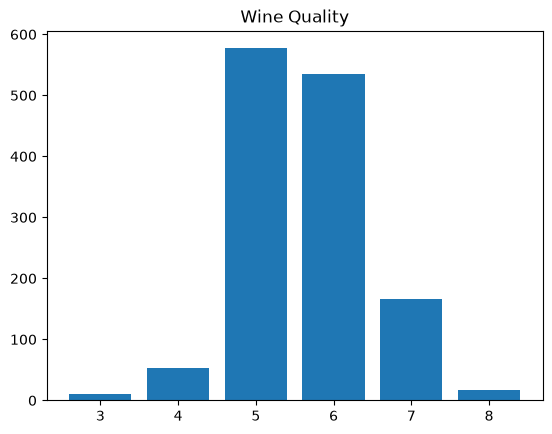

In [19]:
df_quality = df_wine["quality"].value_counts().reset_index(name="count")

plt.bar(x = df_quality["quality"], height = df_quality["count"])
plt.title("Wine Quality")
plt.show()

In [20]:
# Sadece "Ad" ve "Yaş" sütunları aynı olan satırları tekil bırakacak şekilde veri setini temizleyin
import pandas as pd

data = {
    "Ad" : ["Ali","Veli","Ali","Ayşe","Ali"],
    "Yaş" : [25,30,25,22,25],
    "Şehir": ["Ankara","İstanbul","Ankara","İzmir","Ankara"]
}

df = pd.DataFrame(data)
df_partial_unique = df.drop_duplicates(subset= ["Ad","Yaş"])

df_partial_unique

,Ad,Yaş,Şehir
0,Ali,25,Ankara
1,Veli,30,İstanbul
3,Ayşe,22,İzmir


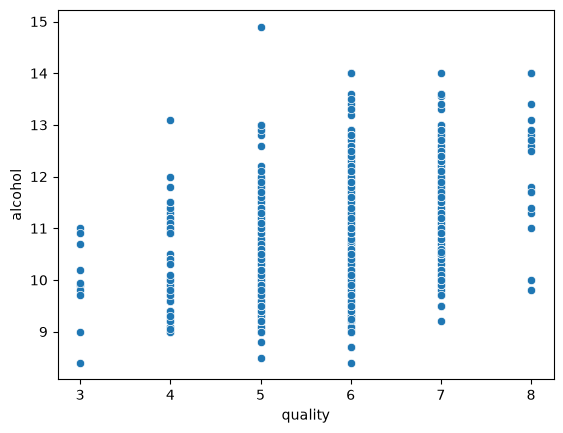

In [21]:
sns.scatterplot(x = "quality", y = "alcohol", data = df_wine)
plt.show()

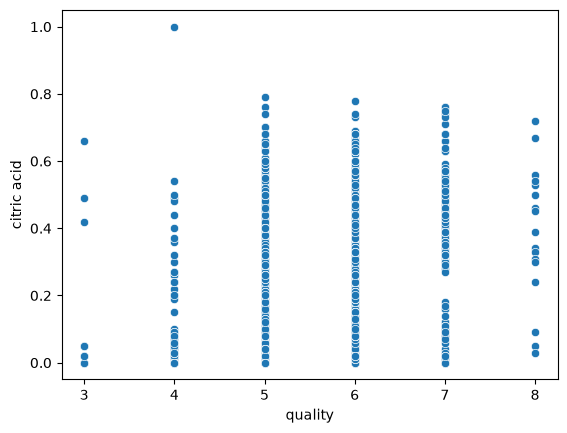

In [23]:
sns.scatterplot(x = "quality", y = "citric acid", data = df_wine)
plt.show()

In [24]:
df_wine.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

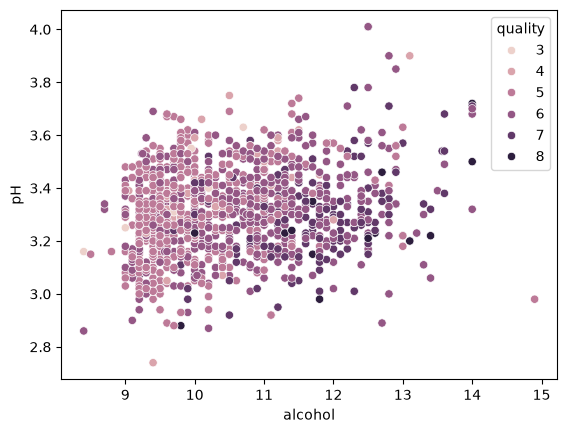

In [26]:
sns.scatterplot(x = "alcohol", y = "pH",hue = "quality", data = df_wine)
plt.show()

In [27]:
df_wine["quality"].value_counts()

quality
5    577
6    535
7    167
4     53
8     17
3     10
Name: count, dtype: int64

In [28]:
df_wine.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

In [35]:
from imblearn.over_sampling import SMOTE

oversample = SMOTE()
X, y = oversample.fit_resample(df_wine[['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol']], df_wine["quality"]) 
print(type(X))
print(type(y))

df_red_wine = pd.concat([X, y], axis= 1)
df_red_wine

<class 'pandas.DataFrame'>
<class 'pandas.Series'>


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.400000,0.700000,0.000000,1.900000,0.076000,11.000000,34.000000,0.997800,3.510000,0.560000,9.400000,5
1,7.800000,0.880000,0.000000,2.600000,0.098000,25.000000,67.000000,0.996800,3.200000,0.680000,9.800000,5
2,7.800000,0.760000,0.040000,2.300000,0.092000,15.000000,54.000000,0.997000,3.260000,0.650000,9.800000,5
3,11.200000,0.280000,0.560000,1.900000,0.075000,17.000000,60.000000,0.998000,3.160000,0.580000,9.800000,6
4,7.400000,0.660000,0.000000,1.800000,0.075000,13.000000,40.000000,0.997800,3.510000,0.560000,9.400000,5
...,...,...,...,...,...,...,...,...,...,...,...,...
3457,8.876270,0.408949,0.450779,1.800000,0.069658,6.552540,14.210161,0.994862,3.272644,0.690000,12.142032,8
3458,5.593245,0.825680,0.048649,1.427022,0.044932,13.080879,87.932445,0.992292,3.555947,0.820000,12.974310,8
3459,5.768605,0.406025,0.264456,2.000000,0.058603,17.602536,42.663313,0.992755,3.548811,0.746987,13.056712,8
3460,5.296075,0.461451,0.115648,1.881570,0.050526,24.329353,71.909561,0.991167,3.589727,0.787372,14.000000,8


In [34]:
df_red_wine["quality"].value_counts()

quality
5    577
6    577
7    577
4    577
8    577
3    577
Name: count, dtype: int64